## Labelling the discussion questions (Goal 3, part 1)

Goal 3 asks for a model that recommends exercises by **threat type, difficulty and required skills**. The exercises already have threat types (from `3_GivingEventsThreatLevel-CISA`, reviewed in `5_goal1_scenario_analysis`), but the `difficulty_level` and `required_skill` columns of the 430 discussion questions are still empty. This notebook fills them in, so the recommender in `8_recommend_exercises` has something to work with.

**Approach:** keyword rules label every question (steps 3–5). Rules are transparent and easy to check and correct. A trained classifier (TF-IDF + logistic regression) is added in step 9b and compared with the rules.

**Checking the rules:** step 8 creates a sheet of 20 questions for the team to label by hand *without* seeing the rule labels. Step 9 compares the two and reports how often they agree.

#### 1. Loading the questions
*Why:* the questions come from `1_cisaFileReading_done`. The empty columns are shown to confirm they still need to be filled.

In [1]:
import re
import pandas as pd
from pathlib import Path

data_dir = Path("../data/processed")
if not data_dir.exists():
    data_dir = Path("data/processed")

questions = pd.read_csv(data_dir / "cisa_discussion_questions.csv")
print("Questions:", len(questions), "| unique texts:", questions["question_text"].nunique())
print("Empty values per column:")
print(questions[["domain_category", "difficulty_level", "required_skill"]].isna().sum().to_string())

pd.set_option("display.max_colwidth", 120)

Questions: 430 | unique texts: 278
Empty values per column:
domain_category     430
difficulty_level    430
required_skill      430


#### 2. Merging the split question in the Executives manual
In the Executives manual, one question is split into six rows: *"…what is your message to:"* followed by *"Employees/customers?"*, *"Management?"*, *"Media?"* and so on.

*Why:* on their own, rows like *"Media?"* cannot be labelled and would count as separate questions. They are joined back into `EX-Q-134` and the fragments are removed. The check stops if the fragments are not where they are expected, so nothing is merged by mistake.

In [2]:
fragment_ids = [f"EX-Q-{i}" for i in range(135, 140)]
by_id = questions.set_index("question_id")["question_text"]

assert by_id["EX-Q-134"].strip().endswith(":"), "EX-Q-134 is not the start of the split question"
assert all(len(by_id[f].split()) <= 2 for f in fragment_ids), "Unexpected fragment text"

questions.loc[questions["question_id"] == "EX-Q-134", "question_text"] = (
    by_id["EX-Q-134"] + " " + " ".join(by_id[f] for f in fragment_ids))
questions = questions[~questions["question_id"].isin(fragment_ids)].reset_index(drop=True)

print("Questions after merging:", len(questions))
print(questions.loc[questions["question_id"] == "EX-Q-134", "question_text"].iloc[0])

Questions after merging: 425
In this scenario, how are you communicating with and what is your message to: Employees/customers? Management? Shareholders/constituents? Partners/contractors/vendors? Media?


#### 3. Skill rules
Each question gets **one** main skill: the skill a participant mostly needs to answer it. The rules are checked **in order** and the first match wins.

*Why the order matters:* many questions touch several topics. For example *"What legal and regulatory notifications are required?"* is about communication *and* law, but the legal part is the harder, more specific skill. So specific skills (legal, communication, third parties) are checked before broad ones (technical controls, incident response). *Incident Response* is the fallback, because every question in an incident exercise is at least about responding.

| Skill | Typical questions |
|---|---|
| Legal & Compliance | law enforcement, notification laws, insurance, evidence |
| Communication | media, public messaging, sharing information, reputation |
| Third-Party Management | vendors, contracts, service-level agreements, supply chain |
| Training & Awareness | employee training, phishing tests, reporting suspicious emails |
| Leadership & Decision-Making | senior leadership, ransom payment, authorising, funding, culture |
| Risk Management | risk assessments, critical assets, greatest threats |
| Business Continuity & Recovery | backups, restoring, manual/alternate processes, redundancy |
| Threat Detection & Monitoring | threat information, monitoring, intrusion detection, abnormal traffic |
| Technical Controls | passwords, MFA, access, patching, encryption, network configuration |
| Incident Response | the incident response plan (CIRP), severity, response actions |

In [3]:
skill_rules = [
    ("Legal & Compliance",
     r"legal|law enforcement|\blaws?\b|regulat|compliance|insurance|evidence"
     r"|notifications? (?:laws|are made|required)|making the notifications"),
    ("Communication",
     r"media|messag|public|\bcommunicat|(?<!zero )(?<!zero-)\btrust\b|sharing|disseminat|reputation|\bbriefed\b"),
    ("Third-Party Management",
     r"vendor|third-party|\btsps?\b|contract|service[- ]level|supply chain|partners?\b|cloud service provider"),
    ("Training & Awareness",
     r"train|phishing test|onboarding|report (?:suspicious|suspected)|users report|employees report|reporting a suspicious"),
    ("Leadership & Decision-Making",
     r"senior leader|leadership|decision|\bauthori[sz]|ransom|\bpay\b|funding|cost-benefit|strategy/plan"
     r"|objectives|culture|approval|policy development|role during"),
    ("Risk Management",
     r"risk assessment|risk management|critical assets|asset management|greatest|most critical"
     r"|possible impacts|potential impacts|risks do you face|posture"),
    ("Business Continuity & Recovery",
     r"backup|backed.up|restor|continuity|coop|\bbcp\b|manual|alternate|alternative|redundan"
     r"|essential (?:functions|services)|downtime|sustain operations|maintain (?:services|availability)|outage"),
    ("Threat Detection & Monitoring",
     r"detect|monitor|intrusion|indicators of compromise|threat information|threat intelligence|intelligence feeds"
     r"|feeds|abnormal|anomal|traffic|baseline|scanning|threat hunting|behavioral indicators"
     r"|sources of information|penetration test"),
    ("Technical Controls",
     r"password|multi-factor|authentication|access|segmentation|network (?:is )?configured|patch|vulnerab"
     r"|encrypt|macro|account|zero.trust|security protocols|hardware|software|legacy|equipment|\bai\b"
     r"|artificial intelligence|controls|secure your network|data loss|disclosure|malware|ddos mitigation|facilities"),
    ("Incident Response",
     r"cirp|incident response|severity|escalation|respond|response|actions|next steps|resources"
     r"|lessons learned|resilience|incident is over"),
]
SKILLS = [name for name, _ in skill_rules]

def label_skill(text):
    text = text.lower()
    for name, pattern in skill_rules:
        if re.search(pattern, text):
            return name
    return "Incident Response"

print(label_skill("What legal and regulatory notifications are required based on the scenario?"))
print(label_skill("How frequently do you run backups?"))

Legal & Compliance
Business Continuity & Recovery


#### 4. Difficulty rules
Difficulty is based on **what kind of thinking** the question asks for, not on the topic:

| Level | What the question asks | Example |
|---|---|---|
| **Basic** | a fact about the organization: yes/no, who, when, how often | *"How frequently do you run backups?"* |
| **Intermediate** | explaining a process or plan | *"How would public messaging be coordinated?"* |
| **Advanced** | weighing options, judging consequences, deciding, learning lessons | *"Discuss the advantages and disadvantages of paying the ransom."* |

*Why:* this follows the idea behind Bloom's taxonomy (remember → apply → evaluate), which is a common way to grade questions. Advanced is checked first, because a question like *"At what point would you contact law enforcement?"* starts like a Basic question but asks for a judgment.

In [4]:
advanced_pattern = (
    r"discuss|advantages|disadvantages|decision|ramifications|lessons learned"
    r"|changes (?:would|will) you implement|regain|cost-benefit|broader impacts|at what point"
    r"|reputational impacts|how will you manage|address concerns|align with your business"
    r"|how have your priorities|prioriti[sz]|risks/advantages|what would you do|describe the impact")

basic_pattern = (
    r"^(?:does|do|is|are|has|how often|how frequently|how long|who|when|where"
    r"|what (?:\w+ ){0,4}(?:does your organization (?:receive|use)|do you use)"
    r"|what are your primary|what type of)")

LEVELS = ["Basic", "Intermediate", "Advanced"]

def label_difficulty(text):
    text = text.lower().strip()
    if re.search(advanced_pattern, text):
        return "Advanced"
    if re.search(basic_pattern, text):
        return "Basic"
    return "Intermediate"

for t in ["How frequently do you run backups?",
          "How would public messaging be coordinated and disseminated during a cyber incident?",
          "Discuss the advantages and disadvantages of either agreeing or refusing to pay the ransom."]:
    print(label_difficulty(t), "|", t)

Basic | How frequently do you run backups?
Intermediate | How would public messaging be coordinated and disseminated during a cyber incident?
Advanced | Discuss the advantages and disadvantages of either agreeing or refusing to pay the ransom.


#### 5. Labelling all questions
*Why:* the rules are applied to every question. The overview shows whether the labels are spread sensibly: if one skill or level took almost all questions, the rules would be too broad to help the recommender tell exercises apart.

In [5]:
questions["required_skill"] = questions["question_text"].map(label_skill)
questions["difficulty_level"] = questions["question_text"].map(label_difficulty)

assert questions["required_skill"].isin(SKILLS).all()
assert questions["difficulty_level"].isin(LEVELS).all()

overview = pd.crosstab(questions["required_skill"], questions["difficulty_level"], margins=True, margins_name="Total")
overview = overview[LEVELS + ["Total"]]
overview = pd.concat([overview.drop("Total").sort_values("Total", ascending=False), overview.loc[["Total"]]])
overview

difficulty_level,Basic,Intermediate,Advanced,Total
required_skill,,,,
Incident Response,9,59,19,87
Business Continuity & Recovery,26,28,2,56
Technical Controls,15,30,1,46
Training & Awareness,16,28,0,44
Risk Management,5,26,6,37
Threat Detection & Monitoring,13,21,1,35
Leadership & Decision-Making,15,10,10,35
Third-Party Management,7,26,1,34
Communication,3,27,3,33


#### 6. Labels per manual
*Why:* a quick plausibility check. Manuals should differ in ways that make sense, for example the Executives manual should have more *Leadership & Decision-Making* questions, and Vendor more *Third-Party Management*.

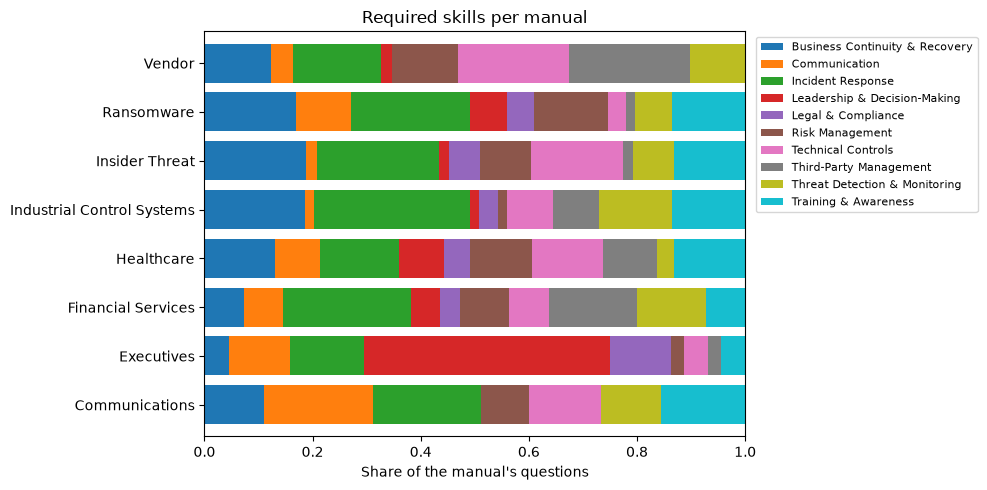

In [6]:
import matplotlib.pyplot as plt

skill_share = pd.crosstab(questions["manual_title"], questions["required_skill"], normalize="index")
ax = skill_share.plot(kind="barh", stacked=True, figsize=(10, 5), colormap="tab10", width=0.8)
ax.set_xlabel("Share of the manual's questions")
ax.set_ylabel("")
ax.set_title("Required skills per manual")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

#### 7. Examples to read through
Three random questions per skill.

*Why:* reading examples is the fastest way to spot a rule that catches the wrong questions. If a label looks wrong, adjust the keywords in step 3 or 4 and run the notebook again.

In [7]:
examples = (questions.drop_duplicates("question_text")
            .groupby("required_skill").sample(n=3, random_state=1)
            .sort_values("required_skill")
            [["required_skill", "difficulty_level", "question_text"]])
examples

,required_skill,difficulty_level,question_text
365,Business Continuity & Recovery,Intermediate,What additional staffing requirements are necessary for alternate systems or procedures?
415,Business Continuity & Recovery,Intermediate,What steps within your CIRP/COOP might help mitigate the TDoS?
314,Business Continuity & Recovery,Basic,How frequently do you test restoration from backups?
257,Communication,Intermediate,"In this scenario, how are you communicating with and what is your message to: Employees/customers? Management? Share..."
378,Communication,Advanced,How would you work to regain public trust and the trust of your customers following this incident?
57,Communication,Intermediate,What pre-scripted messages have been developed for cyber incidents?
143,Incident Response,Intermediate,"Utilizing your organization’s cyber incident response plan (CIRP), describe the actions that your organization would..."
255,Incident Response,Basic,Does your organization have an insider threat management program?
316,Incident Response,Intermediate,What are the roles of your security operations center during a response?
50,Leadership & Decision-Making,Basic,Are ransomware policies/procedures included in your CIRP?


#### 8. Hand-check sheet for the team
20 random questions (unique texts only) are saved to `question_check_sheet.csv` with **empty** columns `team_skill` and `team_difficulty`.

*Why:* the rule labels are not shown on the sheet on purpose, so the person checking is not influenced by them. The sheet is only created if it does not exist yet, so running the notebook again never overwrites the team's answers.

**How to fill it in:** open the CSV in Excel, and for each question write one skill from the table in step 3 and one level (`Basic`, `Intermediate`, `Advanced`) in the two empty columns. Use the exact spelling. Save it as CSV again and push it with GitHub Desktop.

In [8]:
check_path = data_dir / "question_check_sheet.csv"

if check_path.exists():
    print("Check sheet already exists, not overwritten:", check_path)
else:
    sheet = (questions.drop_duplicates("question_text")
             .sample(20, random_state=42)[["question_id", "question_text"]]
             .assign(team_skill="", team_difficulty=""))
    sheet.to_csv(check_path, index=False, encoding="utf-8-sig")
    print("Created:", check_path)

pd.read_csv(check_path)[["question_id", "question_text"]]

Check sheet already exists, not overwritten: ..\data\processed\question_check_sheet.csv


,question_id,question_text
0,HC-Q-129,What processes are used to evaluate and maintain an approved list of patches?
1,RW-Q-137,"Utilizing your organization’s cyber incident response plan (CIRP), describe the actions that your organization would..."
2,VD-Q-147,Describe your policies on remote access to your organization’s network.
3,ICS-Q-154,What redundant systems exist when primary systems are compromised?
4,ICS-Q-156,Does your CIRP include procedures to operate in manual mode if a cyber incident compromises OT systems?
5,IT-Q-152,What capabilities and resources are required to respond to this scenario?
6,ICS-Q-153,Is your CIRP aligned with any OT incident response plans?
7,HC-Q-153,Who can authorize use of alternate systems or procedures?
8,CM-Q-112,What services do you use for intrusion detection monitoring?
9,CM-Q-91,"What cybersecurity threat information does your organization receive (e.g., information from CISA, FBI, Fusion Center)?"


#### 9. Comparing the rules with the team's labels
*Why:* this gives the number to report for the label quality, e.g. *"the rules agreed with the team on 16 of 20 skills"*. If the sheet has not been filled in yet, the cell says so and does nothing. The table of disagreements shows where the rules could be improved.

In [9]:
check = pd.read_csv(check_path, keep_default_na=False)
filled = check[(check["team_skill"].str.strip() != "") & (check["team_difficulty"].str.strip() != "")]

if filled.empty:
    print("The check sheet has not been filled in yet. Fill in team_skill and team_difficulty, then run this cell again.")
else:
    bad_skill = set(filled["team_skill"].str.strip()) - set(SKILLS)
    bad_level = set(filled["team_difficulty"].str.strip()) - set(LEVELS)
    assert not bad_skill and not bad_level, f"Check the spelling of: {bad_skill | bad_level}"

    compared = filled.merge(questions[["question_id", "required_skill", "difficulty_level"]], on="question_id")
    skill_ok = compared["team_skill"].str.strip() == compared["required_skill"]
    level_ok = compared["team_difficulty"].str.strip() == compared["difficulty_level"]

    print(f"Skill agreement:      {skill_ok.sum()} / {len(compared)} ({skill_ok.mean():.0%})")
    print(f"Difficulty agreement: {level_ok.sum()} / {len(compared)} ({level_ok.mean():.0%})")
    display(compared[~(skill_ok & level_ok)][["question_text", "team_skill", "required_skill",
                                              "team_difficulty", "difficulty_level"]])

The check sheet has not been filled in yet. Fill in team_skill and team_difficulty, then run this cell again.


#### 9b. Trained classifier for skill and difficulty
A text classifier (TF-IDF + logistic regression) is trained to predict the skill and difficulty of a question. It learns from the rule labels (this is called *weak supervision*: the training labels come from rules, not from people). The questions on the hand-check sheet are left out of training completely and used as the test set, together with a majority baseline and the rules themselves.

*Why:* this is the trained machine-learning component of Goal 3. The rules only find exact keywords; a classifier can also use other words in the question. The test on the team's blind labels shows which of the two labels questions better. The predictions are saved as `ml_skill` and `ml_difficulty` in step 10.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

# the hand-checked questions are kept out of training completely (all copies of the text)
check = pd.read_csv(check_path, keep_default_na=False)
unique_questions = questions.drop_duplicates("question_text")
train = unique_questions[~unique_questions["question_text"].isin(check["question_text"])]

def make_classifier():
    return make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
                         LogisticRegression(max_iter=2000, class_weight="balanced"))

skill_model = make_classifier().fit(train["question_text"], train["required_skill"])
level_model = make_classifier().fit(train["question_text"], train["difficulty_level"])

# how well the classifier learns the rule labels on questions it has not seen (5-fold cross-validation)
print("Training questions:", len(train))
print(f"Cross-validated agreement with the rules: skill {cross_val_score(make_classifier(), train['question_text'], train['required_skill'], cv=5).mean():.0%}, "
      f"difficulty {cross_val_score(make_classifier(), train['question_text'], train['difficulty_level'], cv=5).mean():.0%}")

# predictions for every question, saved next to the rule labels in step 10
questions["ml_skill"] = skill_model.predict(questions["question_text"])
questions["ml_difficulty"] = level_model.predict(questions["question_text"])

# the real test: compare rules, classifier and a majority baseline with the team's blind labels
filled = check[(check["team_skill"].str.strip() != "") & (check["team_difficulty"].str.strip() != "")]
if filled.empty:
    print("Fill in question_check_sheet.csv first to compare with the team's labels.")
else:
    test = filled.merge(questions.drop_duplicates("question_text")
                        [["question_text", "required_skill", "difficulty_level", "ml_skill", "ml_difficulty"]],
                        on="question_text")
    team_skill = test["team_skill"].str.strip()
    team_level = test["team_difficulty"].str.strip()
    comparison = pd.DataFrame({
        "skill accuracy": {
            "Majority baseline": (team_skill == train["required_skill"].mode()[0]).mean(),
            "Keyword rules": (team_skill == test["required_skill"]).mean(),
            "Trained classifier (TF-IDF + logistic regression)": (team_skill == test["ml_skill"]).mean()},
        "difficulty accuracy": {
            "Majority baseline": (team_level == train["difficulty_level"].mode()[0]).mean(),
            "Keyword rules": (team_level == test["difficulty_level"]).mean(),
            "Trained classifier (TF-IDF + logistic regression)": (team_level == test["ml_difficulty"]).mean()},
    }).round(2)
    print(f"Compared on {len(test)} hand-labelled questions")
    display(comparison)

Training questions: 253
Cross-validated agreement with the rules: skill 60%, difficulty 77%
Fill in question_check_sheet.csv first to compare with the team's labels.


#### 10. Saving the labelled questions
The result is saved as a **new** file, `cisa_questions_labeled.csv`.

*Why a new file:* the original `cisa_discussion_questions.csv` is still read by `app.py` and the other notebooks, so it stays unchanged. The empty `domain_category` column is dropped here because it is not used anywhere.

In [13]:
labeled = questions.drop(columns=["domain_category"])
labeled.to_csv(data_dir / "cisa_questions_labeled.csv", index=False, encoding="utf-8-sig")
print("cisa_questions_labeled.csv:", len(labeled), "rows")

cisa_questions_labeled.csv: 425 rows
